# 04c – Densité des professionnels de santé (Ameli 2024)

Source : [Assurance Maladie](https://www.assurance-maladie.ameli.fr/etudes-et-donnees/densite-professionnels-sante-liberaux-departement)

Limites :
- seuls les médecins libéraux sont comptés, pas ceux de l'hôpital
- la densité est calculée sur les habitants, les touristes ne sont pas comptés
- la densité des pédiatres est calculée sur les 0-19 ans

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Importation des données

In [13]:
fichier_ameli = pd.ExcelFile('../data/raw/Socio Eco/ameli_densite_2024.xls')
print(fichier_ameli.sheet_names)

ameli_gen = pd.read_excel(fichier_ameli, sheet_name='Généralistes et MEP')
ameli_spe = pd.read_excel(fichier_ameli, sheet_name='Spécialistes')
ameli_aux = pd.read_excel(fichier_ameli, sheet_name='Auxiliaires médicaux')

ameli_gen.head()

['Lisez moi', 'Nomenclature des PS', 'Spécialistes', 'Généralistes et MEP', 'Dentistes et ODF', 'Sages-femmes', 'Auxiliaires médicaux', 'Laboratoires', 'Psychologues']


,Généralistes et compétence MEP,DEPARTEMENT,EFFECTIF,POPULATION FRANCAISE,DENSITE /100 000 hab.
0,01- Médecine générale,01- Ain,368,688626,53.439748
1,01- Médecine générale,02- Aisne,311,518817,59.944065
2,01- Médecine générale,03- Allier,221,332599,66.446381
3,01- Médecine générale,04- Alpes-Hte-Provence,152,169806,89.513916
4,01- Médecine générale,05- Hautes-Alpes,178,142006,125.346816


Le fichier a 9 onglets. Je garde les 3 qui concernent les maladies respiratoires. Une ligne = une catégorie de professionnels dans un département.

## 2. Contrôle des données

In [14]:
onglets = [ameli_gen, ameli_spe, ameli_aux]
noms_onglets = ['Généralistes et MEP', 'Spécialistes', 'Auxiliaires médicaux']

for i in range(3):
    tableau = onglets[i]
    print("Onglet", noms_onglets[i])
    print("taille :", tableau.shape)
    print("colonnes :", list(tableau.columns))
    print(tableau.head(3))
    print("nombre de catégories :", tableau.iloc[:, 0].nunique())
    print("cases vides :", tableau.isna().sum().sum())
    print("lignes en double :", tableau.duplicated().sum())
    print("----------------------------------------------------------------------------------")

# les lignes qui ne sont pas des départements
print(list(ameli_gen[ameli_gen['DEPARTEMENT'].str.contains('TOTAL')]['DEPARTEMENT'].unique()))

Onglet Généralistes et MEP
taille : (6968, 5)
colonnes : ['Généralistes et compétence MEP', 'DEPARTEMENT', 'EFFECTIF', 'POPULATION FRANCAISE', 'DENSITE /100 000 hab.']
  Généralistes et compétence MEP DEPARTEMENT  EFFECTIF  POPULATION FRANCAISE  \
0          01- Médecine générale     01- Ain       368                688626   
1          01- Médecine générale   02- Aisne       311                518817   
2          01- Médecine générale  03- Allier       221                332599   

   DENSITE /100 000 hab.  
0              53.439748  
1              59.944065  
2              66.446381  
nombre de catégories : 67
cases vides : 0
lignes en double : 0
----------------------------------------------------------------------------------
Onglet Spécialistes
taille : (5928, 5)
colonnes : ['Spécialistes', 'DEPARTEMENT', 'EFFECTIF', 'POPULATION FRANCAISE', 'DENSITE /100 000 hab.']
                              Spécialistes DEPARTEMENT  EFFECTIF  \
0  02- Anesthésie-réanimation chirurgicale    

Pas de cases vides ni de lignes en double. Chaque catégorie a 104 lignes : 101 départements et 3 lignes de total (France métropolitaine, Outre-mer, France entière) que je retire.

Certaines catégories sont aussi des totaux (TOTAL MEDECINS, OMNIPRATICIENS, MEP...). Je ne les utilise pas pour ne pas compter deux fois les mêmes médecins.

## 3. Choix des professions

In [15]:
recap_par_onglet = []

for i in range(3):
    tableau = onglets[i]
    # on enlève les lignes de total des départements
    departements = tableau[tableau['DEPARTEMENT'].str.contains('TOTAL') == False]
    categorie = tableau.columns[0]

    recap_onglet = pd.DataFrame()
    recap_onglet['nb_france'] = departements.groupby(categorie)['EFFECTIF'].sum()
    zero = departements[departements['EFFECTIF'] == 0]
    recap_onglet['nb_dep_sans_aucun'] = zero.groupby(categorie)['EFFECTIF'].count()
    recap_onglet['onglet'] = noms_onglets[i]
    recap_par_onglet.append(recap_onglet)

recap_ameli = pd.concat(recap_par_onglet)
recap_ameli = recap_ameli.fillna(0)
recap_ameli['nb_dep_sans_aucun'] = recap_ameli['nb_dep_sans_aucun'].astype(int)

# on enlève aussi les catégories qui sont des totaux (sommes d'autres catégories)
a_enlever = []
for nom in recap_ameli.index:
    if 'TOTAL' in nom or nom == '01- OMNIPRATICIENS' or nom == '01- M.E.P.':
        a_enlever.append(nom)
recap_ameli = recap_ameli.drop(a_enlever)

# afficher toutes les lignes
pd.set_option('display.max_rows', 200)
recap_ameli.sort_values(['onglet', 'nb_france'], ascending=[True, False])

,nb_france,nb_dep_sans_aucun,onglet
24- Infirmiers,98628,0,Auxiliaires médicaux
26- Masseurs-kinésithérapeutes-rééducateurs,82101,0,Auxiliaires médicaux
28- Orthophonistes,21763,0,Auxiliaires médicaux
27- Pédicures,13025,0,Auxiliaires médicaux
29- Orthoptistes,3245,0,Auxiliaires médicaux
86- Infirmiers de pratiques avancées,395,16,Auxiliaires médicaux
01- Médecine générale,51775,0,Généralistes et MEP
60- Homéopathie et Médecine Générale,618,13,Généralistes et MEP
41- Acupuncture et Médecine Générale,572,17,Généralistes et MEP
92- Médecine d'urgence et Médecine Générale,532,30,Généralistes et MEP


Pour chaque catégorie : le nombre de professionnels en France et le nombre de départements où il n'y en a aucun.

In [16]:
retenues = ['01- Médecine générale', '12- Pédiatrie', '13- Pneumologie',
            '85-Allergologie', '04- Allergologie', '42- Allergologie et Médecine Générale',
            '93- SOS Médecins', '26- Masseurs-kinésithérapeutes-rééducateurs']

recap_ameli.loc[retenues]

,nb_france,nb_dep_sans_aucun,onglet
01- Médecine générale,51775,0,Généralistes et MEP
12- Pédiatrie,2710,2,Spécialistes
13- Pneumologie,1223,1,Spécialistes
85-Allergologie,277,25,Spécialistes
04- Allergologie,29,77,Généralistes et MEP
42- Allergologie et Médecine Générale,69,62,Généralistes et MEP
93- SOS Médecins,431,52,Généralistes et MEP
26- Masseurs-kinésithérapeutes-rééducateurs,82101,0,Auxiliaires médicaux


enlevé : 01- Médecine générale


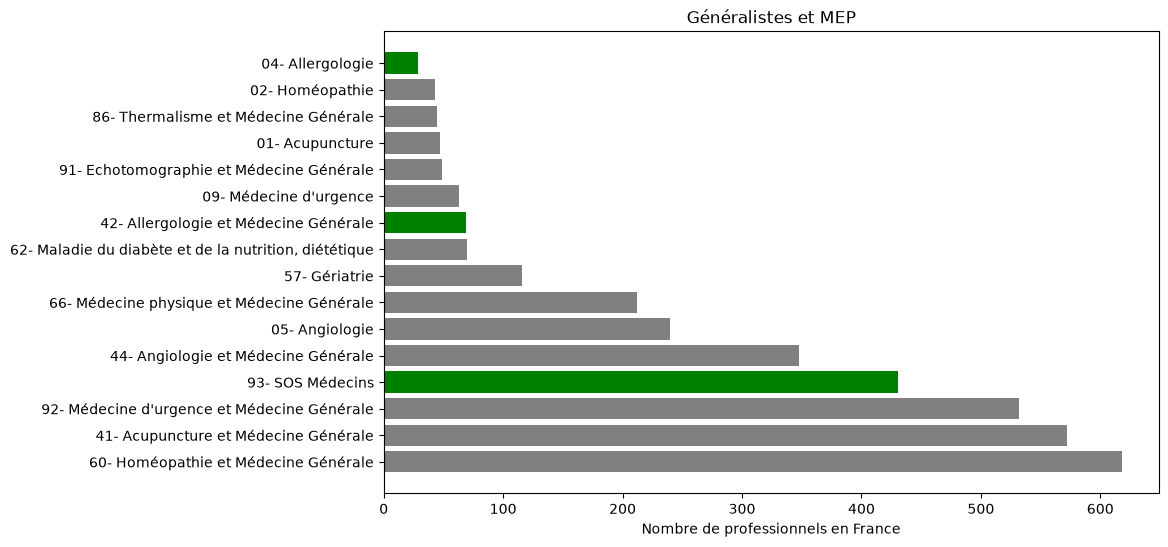

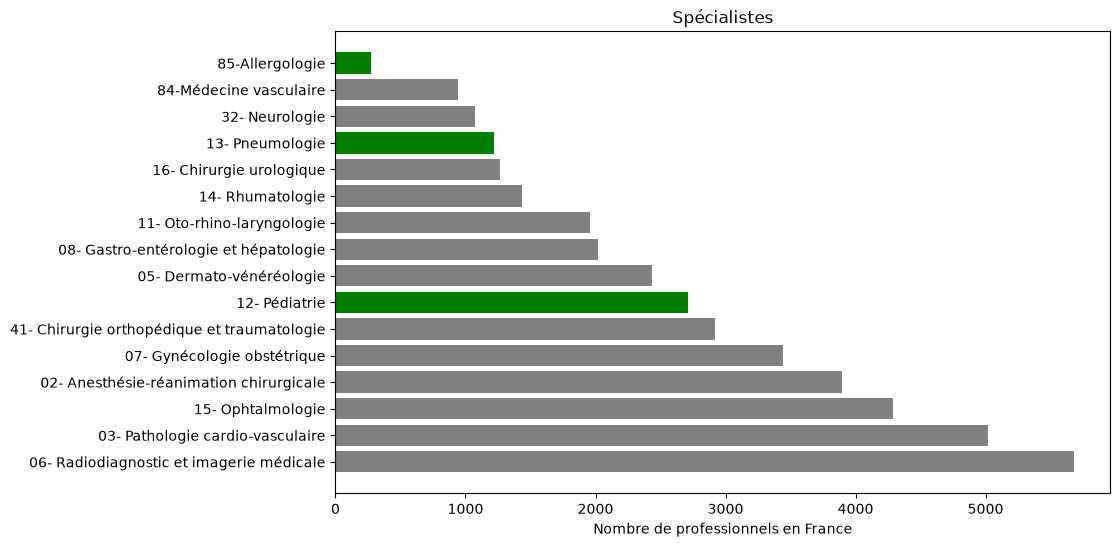

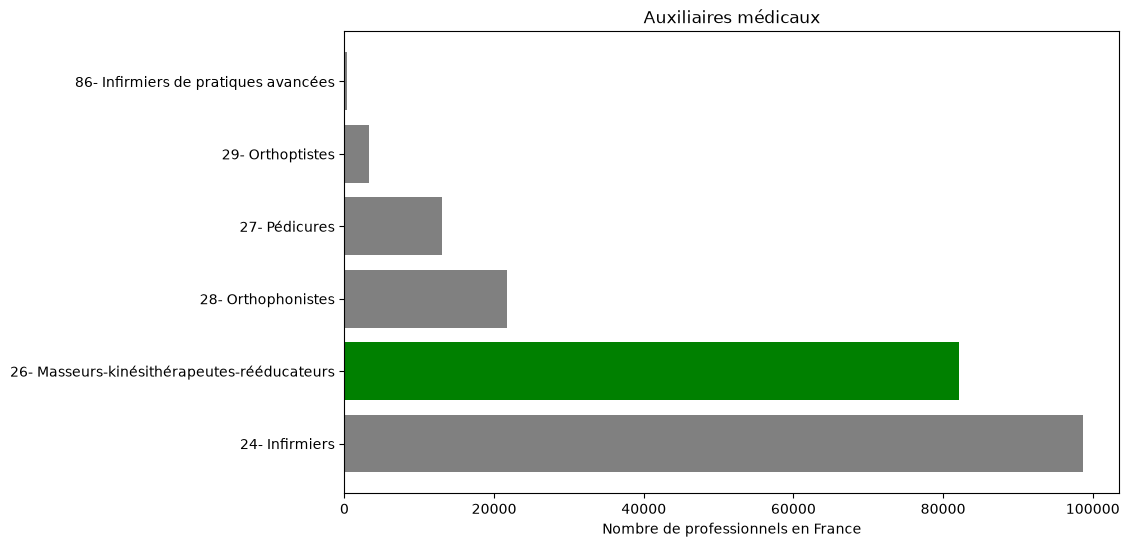

In [17]:
for i in range(3):
    donnees = recap_ameli[recap_ameli['onglet'] == noms_onglets[i]]
    donnees = donnees.sort_values('nb_france', ascending=False)

    noms = []
    valeurs = []
    couleurs = []

    for nom in donnees.index:
        # on ne garde pas les totaux, ni la médecine générale (trop grande)
        if nom == '01- Médecine générale':
            print('enlevé :', nom)
        # on garde les 15 plus grandes et les professions retenues
        elif len(noms) < 15 or nom in retenues:
            noms.append(nom)
            valeurs.append(donnees.loc[nom, 'nb_france'])
            if nom in retenues:
                couleurs.append('green')
            else:
                couleurs.append('grey')

    plt.figure(figsize=(10, 6))
    plt.barh(noms, valeurs, color=couleurs)
    plt.title(noms_onglets[i])
    plt.xlabel('Nombre de professionnels en France')
    plt.show()

En vert les professions que je garde. J'ai retiré la médecine générale du premier graphique (51 775 médecins) car elle écrasait les autres barres.

Je garde les professions qui ont un lien direct avec les maladies respiratoires :
- les généralistes
- les pédiatres (bronchiolite, asthme de l'enfant)
- les pneumologues (asthme)
- les allergologues (allergies), j'additionne les 3 catégories car ce sont des médecins différents
- SOS Médecins (présent dans 49 départements seulement)
- les kinés (kiné respiratoire)

Je ne garde pas les urgentistes car ils travaillent surtout à l'hôpital, donc ils ne sont presque pas dans ce fichier. Les ORL et les infirmiers ont un lien moins direct.

Attention, certaines professions sont rares (17 départements sans allergologue). Une seule personne qui s'installe ou qui part peut faire beaucoup varier la densité.

## 4. Nettoyage

In [18]:
# [onglet, catégorie, nom de la colonne]
professions = [[ameli_gen, '01- Médecine générale', 'nb_generalistes'],
               [ameli_spe, '12- Pédiatrie', 'nb_pediatres'],
               [ameli_spe, '13- Pneumologie', 'nb_pneumologues'],
               [ameli_spe, '85-Allergologie', 'nb_allergo_1'],
               [ameli_gen, '04- Allergologie', 'nb_allergo_2'],
               [ameli_gen, '42- Allergologie et Médecine Générale', 'nb_allergo_3'],
               [ameli_gen, '93- SOS Médecins', 'nb_sos'],
               [ameli_aux, '26- Masseurs-kinésithérapeutes-rééducateurs', 'nb_kines']]

# on part de la liste des départements avec leur population
lignes = ameli_gen[ameli_gen.iloc[:, 0] == '01- Médecine générale']
lignes = lignes[lignes['DEPARTEMENT'].str.contains('TOTAL') == False]
ameli_propre = lignes[['DEPARTEMENT', 'POPULATION FRANCAISE']].set_index('DEPARTEMENT')
ameli_propre.columns = ['population']

# on ajoute une colonne par profession
for onglet, categorie, nom_colonne in professions:
    lignes = onglet[onglet.iloc[:, 0] == categorie]
    lignes = lignes[lignes['DEPARTEMENT'].str.contains('TOTAL') == False]
    ameli_propre[nom_colonne] = lignes.set_index('DEPARTEMENT')['EFFECTIF']

# population des 0-19 ans pour les pédiatres
lignes = ameli_spe[ameli_spe.iloc[:, 0] == '12- Pédiatrie']
lignes = lignes[lignes['DEPARTEMENT'].str.contains('TOTAL') == False]
ameli_propre['population_0_19'] = lignes.set_index('DEPARTEMENT')['POPULATION FRANCAISE']

ameli_propre.head()

,population,nb_generalistes,nb_pediatres,nb_pneumologues,nb_allergo_1,nb_allergo_2,nb_allergo_3,nb_sos,nb_kines,population_0_19
DEPARTEMENT,,,,,,,,,,
01- Ain,688626,368,9,7,1,0,1,0,533,130845
02- Aisne,518817,311,9,16,1,0,3,1,294,90657
03- Allier,332599,221,5,5,0,0,1,0,351,47686
04- Alpes-Hte-Provence,169806,152,10,1,1,0,0,1,241,25441
05- Hautes-Alpes,142006,178,0,0,0,0,0,0,383,20206


In [19]:
# allergologues : on additionne les 3 catégories
ameli_propre['nb_allergologues'] = ameli_propre['nb_allergo_1'] + ameli_propre['nb_allergo_2'] + ameli_propre['nb_allergo_3']
ameli_propre = ameli_propre.drop(columns=['nb_allergo_1', 'nb_allergo_2', 'nb_allergo_3'])#drop pour supp les anciennes colonnes allergo


# densités pour 100 000 habitants
ameli_propre['densite_generalistes'] = ameli_propre['nb_generalistes'] / ameli_propre['population'] * 100000
ameli_propre['densite_pediatres'] = ameli_propre['nb_pediatres'] / ameli_propre['population_0_19'] * 100000
ameli_propre['densite_pneumologues'] = ameli_propre['nb_pneumologues'] / ameli_propre['population'] * 100000
ameli_propre['densite_allergologues'] = ameli_propre['nb_allergologues'] / ameli_propre['population'] * 100000
ameli_propre['densite_kines'] = ameli_propre['nb_kines'] / ameli_propre['population'] * 100000

# SOS Médecins présent ou non
ameli_propre['sos_present'] = ameli_propre['nb_sos'] > 0

# séparer le code et le nom du département
ameli_propre = ameli_propre.reset_index()
ameli_propre[['code_dep', 'nom_dep']] = ameli_propre['DEPARTEMENT'].str.split('- ', n=1, expand=True)
ameli_propre = ameli_propre.drop(columns=['DEPARTEMENT'])

# DROM (code qui commence par 97)
ameli_propre['est_drom'] = ameli_propre['code_dep'].str.startswith('97')

# on range les colonnes dans l'ordre : département d'abord
ameli_propre = ameli_propre[['code_dep', 'nom_dep', 'est_drom', 'population', 'population_0_19',
                             'nb_generalistes', 'nb_pediatres', 'nb_pneumologues', 'nb_allergologues', 'nb_kines', 'nb_sos',
                             'densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines',
                             'sos_present']]

ameli_propre.head()

,code_dep,nom_dep,est_drom,population,population_0_19,nb_generalistes,nb_pediatres,nb_pneumologues,nb_allergologues,nb_kines,nb_sos,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,01,Ain,False,688626,130845,368,9,7,2,533,0,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,02,Aisne,False,518817,90657,311,9,16,4,294,1,59.944065,9.927529,3.083939,0.770985,56.667380,True
2,03,Allier,False,332599,47686,221,5,5,1,351,0,66.446381,10.485258,1.503312,0.300662,105.532488,False
3,04,Alpes-Hte-Provence,False,169806,25441,152,10,1,1,241,1,89.513916,39.306631,0.588907,0.588907,141.926669,True
4,05,Hautes-Alpes,False,142006,20206,178,0,0,0,383,0,125.346816,0.000000,0.000000,0.000000,269.706914,False


nb_sos ne compte que les médecins déclarés SOS Médecins, c'est donc incomplet : 52 départements ont 0 alors qu'il existe 63 associations en France.
On garde nb_sos et sos_present (présent/absent) pour l'instant, à voir avec le groupe.

## 5. Inspection

In [20]:
print(ameli_propre.shape)
print(ameli_propre['est_drom'].value_counts())
print("cases vides :", ameli_propre.isna().sum().sum())

densites = ['densite_generalistes', 'densite_pediatres', 'densite_pneumologues', 'densite_allergologues', 'densite_kines']
ameli_propre[densites].describe().round(1)

(101, 17)
est_drom
False    96
True      5
Name: count, dtype: int64
cases vides : 0


,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines
count,101.0,101.0,101.0,101.0,101.0
mean,73.4,19.3,1.6,0.5,114.5
std,18.1,12.9,0.9,0.4,48.8
min,8.8,0.0,0.0,0.0,19.4
25%,59.3,10.5,0.9,0.3,77.4
50%,74.8,17.5,1.5,0.4,102.0
75%,87.1,23.9,2.1,0.6,140.1
max,125.3,87.2,4.3,2.2,269.7


101 départements (96 en métropole et 5 DROM), pas de cases vides.

Les densités varient beaucoup selon les départements, par exemple de 8,8 à 125,3 généralistes pour 100 000 habitants.

## 6. Visualisation

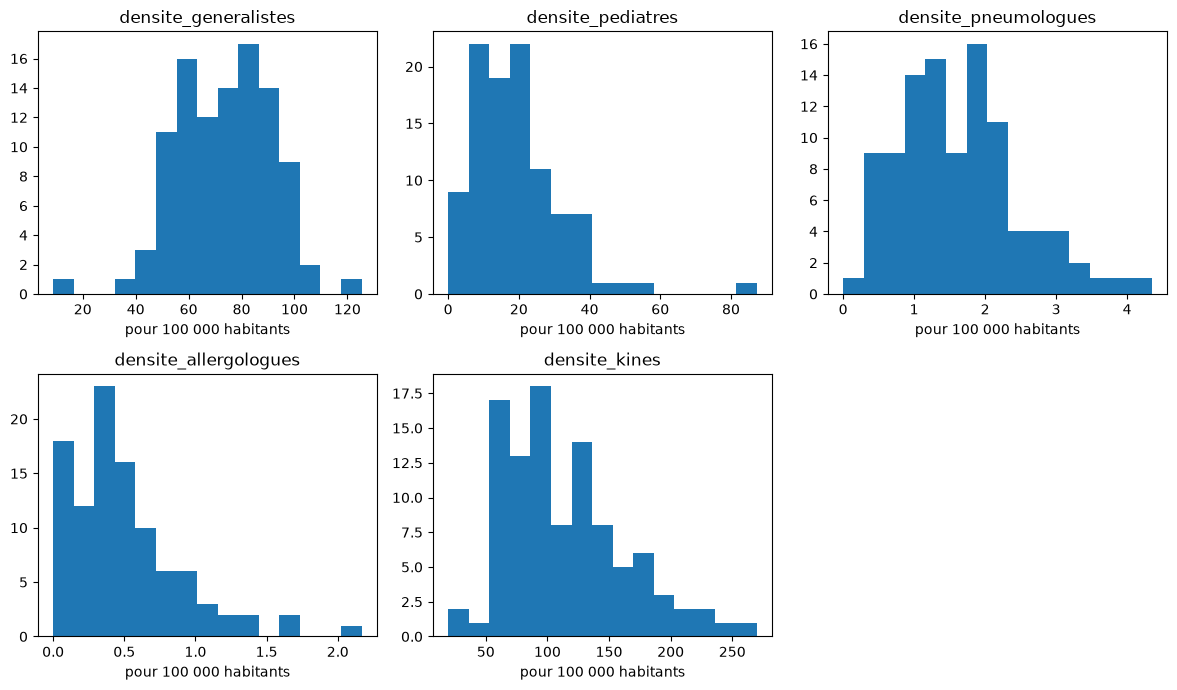

In [21]:
plt.figure(figsize=(12, 7))

for i in range(5):
    plt.subplot(2, 3, i + 1) #(le nombre de lignes, le nombre de colonnes, la case )
    plt.hist(ameli_propre[densites[i]], bins=15)
    plt.title(densites[i])
    plt.xlabel('pour 100 000 habitants')

plt.tight_layout()
plt.show()

Les généralistes et les kinés sont présents partout, avec de grandes différences entre départements. Les allergologues sont très peu nombreux, souvent proches de zéro.

In [22]:
# les 10 départements avec le moins de généralistes et les 10 avec le plus
print(ameli_propre.sort_values('densite_generalistes')[['nom_dep', 'densite_generalistes']].head(10))
print(ameli_propre.sort_values('densite_generalistes')[['nom_dep', 'densite_generalistes']].tail(10))

            nom_dep  densite_generalistes
100         Mayotte              8.807041
98           Guyane             32.836903
93   Seine-St-Denis             44.103662
17             Cher             45.972349
77   Seine-et-Marne             46.430997
28     Eure-et-Loir             47.789670
91          Essonne             48.454553
89            Yonne             50.433212
95       Val-d'Oise             50.870270
27             Eure             53.327397
                 nom_dep  densite_generalistes
16     Charente-Maritime             96.968310
29             Finistère             97.517939
67              Bas-Rhin             98.915946
12      Bouches-du-Rhône             99.319451
99               Réunion            100.538399
33               Gironde            100.718353
5        Alpes-Maritimes            101.685915
64  Pyrénées-Atlantiques            103.856860
73                Savoie            106.364433
4           Hautes-Alpes            125.346816


Les moins bien dotés : Mayotte, la Guyane, Ile-de-France (Seine-Saint-Denis, Essonne...) et une partie du Centre. Les mieux dotés : la montagne et le littoral, sans doute à cause des touristes.